In [45]:
using LinearAlgebra
using DifferentialEquations, Plots
using BenchmarkTools
using HypothesisTests
default(grid=false,legend=false, size=(400,320), dpi=300, tickfontsize=16, lw=2, lc=:gray, labelfontsize=16, tickdir=:out, fontfamily="Arial", legendfontsize=13, markercolor=:indianred)

mydir = "../helper/"
include(mydir * "base.jl")
include(mydir * "optimization.jl")
include(mydir * "misc.jl")

annotate_exp_traj (generic function with 2 methods)

### Load data

In [2]:
using DelimitedFiles
# INSERT YOUR OWN DATA DIRECTORY AND FILENAME HERE
# E. coli MG1655 (CGSC 6300)/20090131/xy01c1/ch1_cell0.dat
data_dir = "/Volumes/Chenyi/MIT/research/Cell_growth/data/CurrBiol10/E_coli_MG1655/"
DT = 1/60; # convert to hours
DL = 0.0645; # convert to um

In [3]:
# # manual selection

# data_date = "20090131/"
# data_fov = "xy14c1/"
# filename_all = readdir(data_dir*data_date*data_fov);
# select_cache = filename_all[ contains.(filename_all, "_cell0.dat") ]

# idx=1
# tab_cache=readdlm(data_dir * data_date * data_fov * select_cache[idx]);
# varnames = convert(Vector{String}, tab_cache[1,:]);
# tt = tab_cache[2:end,findfirst(varnames .== "index")] * DT;
# LL = tab_cache[2:end,findfirst(varnames .== "length")] * DL;
# data_date * data_fov * select_cache[idx]
# tmp = [(0,50.0)]
# pp = plot(tt, LL, size=(1500,300),bottommargin=7Plots.mm, leftmargin=5Plots.mm)
# for i in eachindex(tmp)
#     plot!(pp, tt[ (tt.>tmp[i][1]) .& (tt .< tmp[i][2]) ], LL[(tt.>tmp[i][1]) .& (tt .< tmp[i][2])],lc=:indianred)
# end

In [5]:
# INSERT SELECTED FILES AND TIME WINDOWS HERE.

select_filename =[
    "20090131/xy01c1/ch0_cell0.dat",
    "20090131/xy01c1/ch1_cell0.dat",
    "20090131/xy01c1/ch2_cell0.dat",
    "20090131/xy01c1/ch3_cell0.dat",
    "20090131/xy01c1/ch4_cell0.dat",
    "20090131/xy01c1/ch5_cell0.dat",
    "20090131/xy01c1/ch6_cell0.dat",
    "20090131/xy02c1/ch0_cell0.dat",
    "20090131/xy03c1/ch0_cell0.dat",
    "20090131/xy04c1/ch0_cell0.dat",
    "20090131/xy04c1/ch1_cell0.dat",
    "20090131/xy05c1/ch0_cell0.dat",
    "20090131/xy05c1/ch1_cell0.dat",
    "20090131/xy05c1/ch2_cell0.dat",
    "20090131/xy05c1/ch3_cell0.dat",
    "20090131/xy06c1/ch0_cell0.dat",
    "20090131/xy06c1/ch1_cell0.dat",
    "20090131/xy06c1/ch2_cell0.dat",
    "20090131/xy06c1/ch3_cell0.dat",
    "20090131/xy07c1/ch0_cell0.dat",
    "20090131/xy07c1/ch1_cell0.dat",
    "20090131/xy07c1/ch2_cell0.dat",
    "20090131/xy07c1/ch3_cell0.dat",
    "20090131/xy07c1/ch4_cell0.dat",
    "20090131/xy07c1/ch5_cell0.dat",
    "20090131/xy08c1/ch0_cell0.dat",
    "20090131/xy08c1/ch1_cell0.dat",
    "20090131/xy08c1/ch2_cell0.dat",
    "20090131/xy08c1/ch3_cell0.dat",
    "20090131/xy08c1/ch4_cell0.dat",
    "20090131/xy09c1/ch0_cell0.dat",
    "20090131/xy09c1/ch1_cell0.dat",
    "20090131/xy09c1/ch2_cell0.dat",
    "20090131/xy09c1/ch3_cell0.dat",
    "20090131/xy10c1/ch0_cell0.dat",
    "20090131/xy10c1/ch1_cell0.dat",
    "20090131/xy10c1/ch2_cell0.dat",
    "20090131/xy11c1/ch0_cell0.dat",
    "20090131/xy12c1/ch0_cell0.dat",
    "20090131/xy12c1/ch1_cell0.dat",
    "20090131/xy12c1/ch2_cell0.dat",
    "20090131/xy12c1/ch3_cell0.dat",
    "20090131/xy12c1/ch4_cell0.dat",
    "20090131/xy12c1/ch5_cell0.dat",
    "20090131/xy12c1/ch6_cell0.dat",
    "20090131/xy12c1/ch7_cell0.dat",
    "20090131/xy13c1/ch0_cell0.dat",
    "20090131/xy13c1/ch1_cell0.dat",
    "20090131/xy13c1/ch2_cell0.dat",
    "20090131/xy14c1/ch0_cell0.dat",
]

select_time_all = [
    [(0.0, 11.0), (12.6, 26.8), (33.3, 46.8), (51.6, 60.8)],
    [(0.0, 20.8), (21.6, 34.3)],
    [(0.0, 24.0),(27.0,46.0)],
    [(52.,65.0)],
    [(58.,65.0)],
    [(51.5,64.0)],
    [(53.0,64.3)],
    [(0.0,18.55), (19.5,31.0)],
    [(0.0,29.5)],
    [(0.0,16.0), (21.0, 43.0)],
    [(0.0,4.0), (5.0, 21.8), (26.5,46.0)],
    [(0.0,8.5), (9.5, 32.8)],
    [(0.0,25.5), (26.2, 32.5)],
    [(0.0,20.1)],
    [(55.0,65.0)],
    [(0.0,13.5),(18.5,34.0)],
    [(0.0,27.9)],
    [(0.0,19.0),(22.5,34.5)],
    [(48.0,65.0)],
    [(0.0,14.2),(15.5,30.5)],
    [(0.0,12.5),(13.3,19.2),(22.0,48.0),(50.0,60.5)],
    [(1.3,22.0),(25.5,49.8),(52.5,65.0)],
    [(37.0,54.0)],
    [(40.2,61.0)],
    [(50.0,64.5)],
    [(0.0,40.5),(41.8,55.2)],
    [(0.0,39.5)],
    [(0.0, 21.0),(24.2,40.0)],
    [(48.0,65.0)],
    [(62.0,65.0)],
    [(4.5, 34.5), (36.5,56.0)],
    [(0.0,40.0)],
    [(0.0,4.3),(5.3,13.0),(13.5,44.0),(46.0,61.6)],
    [(58.0,65.0)],
    [(2.2,22.0)],
    [(0.0,18.5),(37.0,54.0)],
    [(58.0,65.0)],
    [(1.3,38.0)],
    [(0.,24.0),(31.0,39.4),(42.3,60.0)],
    [(41.5,65.0)],
    [(43.0,64.5)],
    [(43.6,65.0)],
    [(50.0,65.0)],
    [(44.0,65.0)],
    [(50.0,65.0)],
    [(50.0,65.0)],
    [(0.1,7.0),(8.2,43.4)],
    [(39.0,44.8),(50.4,63.6)],
    [(53.5,60.0)],
    [(0.0,50.0)]
]

# annotate
Lobs_ = []
tobs_ = []
for idx in eachindex(select_filename)
    tab = readdlm(data_dir * select_filename[idx]);
    varnames = convert(Vector{String}, tab[1,:]);
    tobs = tab[2:end,findfirst(varnames .== "index")] * DT;
    Lobs = tab[2:end,findfirst(varnames .== "length")] * DL;
    Lobs_idx, tobs_idx = filter_exp_traj(Lobs, tobs; select_time = select_time_all[idx] );
    Lobs_ = vcat(Lobs_, Lobs_idx)
    tobs_ = vcat(tobs_, tobs_idx)
end
Lobs_ = convert.(Vector{Float64}, Lobs_);
tobs_ = convert.(Vector{Float64}, tobs_);


In [6]:
(size(select_filename) == size(select_time_all)) && (@show size(select_filename);)


size(select_filename) = (50,)


(50,)

In [7]:
isdiv_, dtobs_ = annotate_exp_traj(Lobs_, tobs_);

In [8]:
sum(sum.(isdiv_))

3916

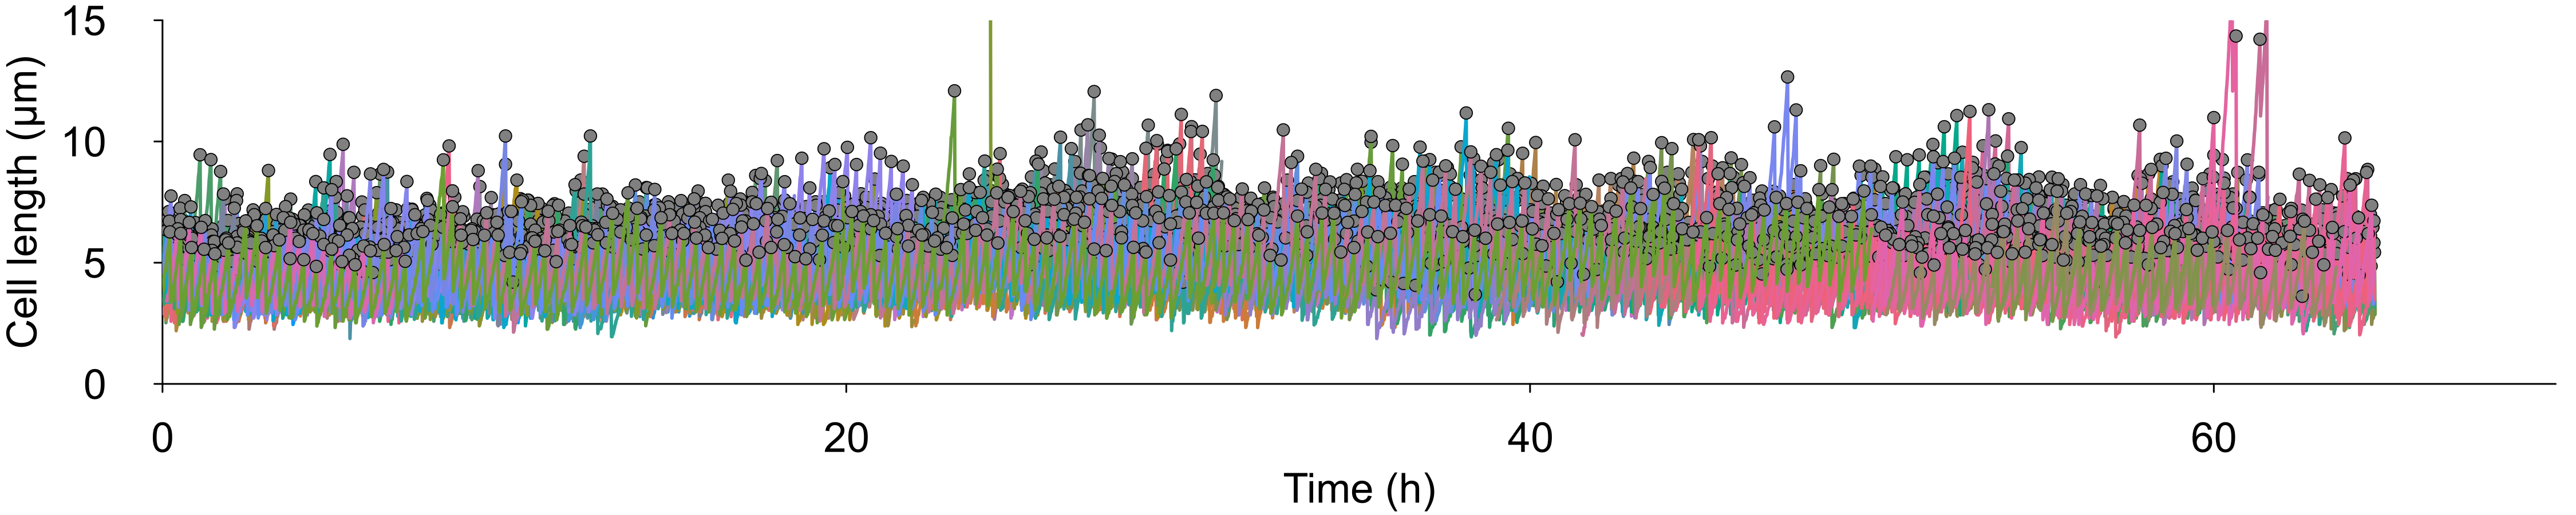

In [9]:
p_traj_obs = plot(; size=(1500,300), xlim=(0,70), ylim=(0,15), xtick=collect(0:20:80), ytick=collect(0:5:15), bottommargin=12Plots.mm,  leftmargin=9Plots.mm, xlabel="Time (h)", ylabel="Cell length (μm)")
linecolor_ = palette(:default, length(Lobs_) )
for i in eachindex(Lobs_)
    plot!(p_traj_obs, tobs_[i], Lobs_[i], lc=linecolor_[i])
    scatter!(p_traj_obs, tobs_[i][isdiv_[i]], Lobs_[i][isdiv_[i]], markercolor=:gray)
end
p_traj_obs

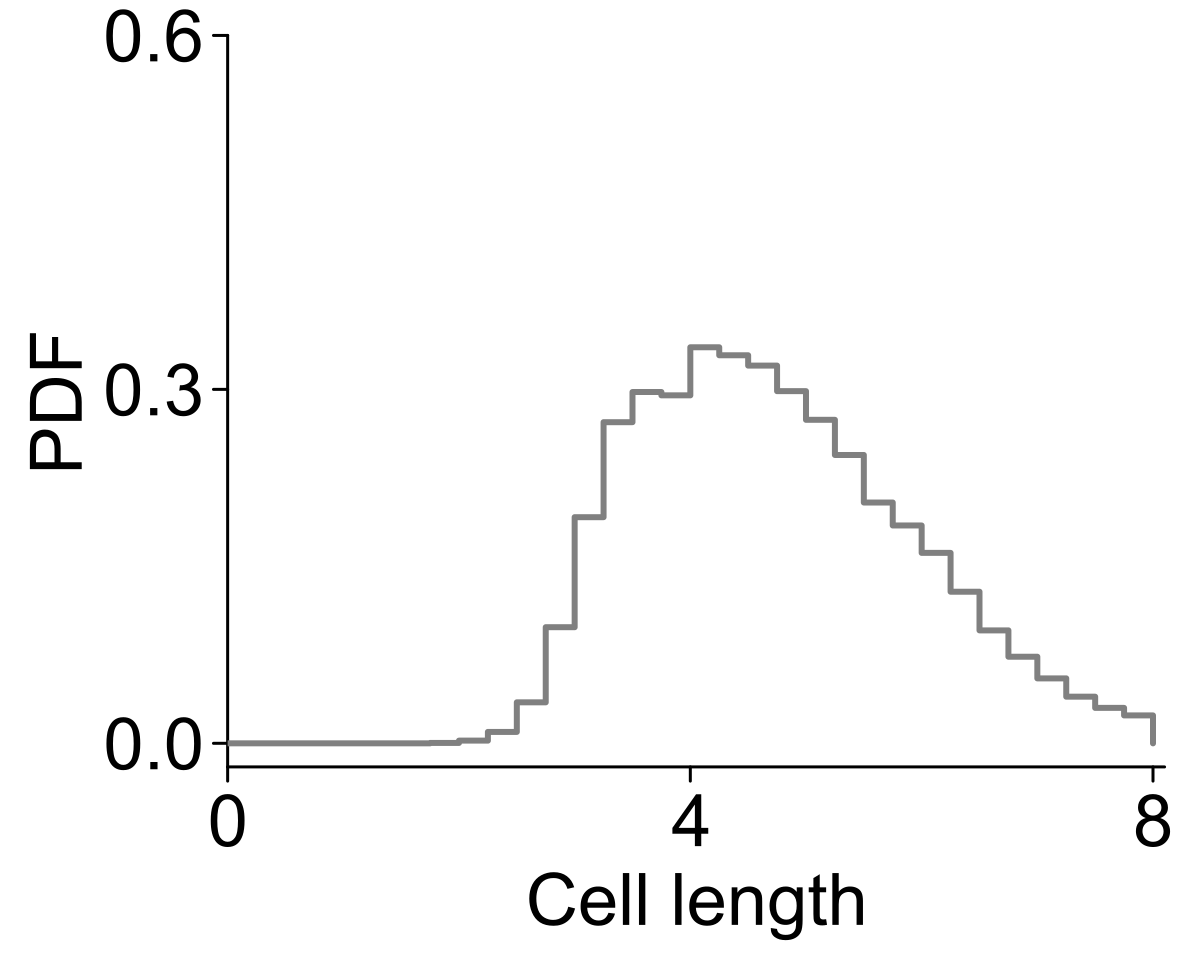

In [47]:
p1 = plot(;xlim=(0,8.1), xtick=[0,4,8],ylim=(-0.02,0.6),ytick=[0,0.3,0.6])
stephist!( p1, vcat(Lobs_...), bins=collect(0:0.25:8), normalize=:pdf, xlabel="Cell length", ylabel="PDF")


In [35]:
n_func = 11;
basis_func = Polynomial()
Θ, Σ = gen_ortho_bases(vcat(Lobs_...), n_func-1);
# _, Σ = gen_ortho_bases(collect(0.:0.01:15.0), n_func-1, basis_func);
# Θ = gen_ortho_bases(vcat(Lobs_...), Σ, basis_func);
Θdiv = Θ[vcat(isdiv_...),:];
Θdiv = sum(Θdiv, dims=1)[:];

In [ ]:
# _, coeffs_sparse = sparse_optimization(Θ, Θdiv, vcat(dtobs_...); EPSILON=1E-7, MAX_ITERS=40);

In [46]:
history = sparse_optimization_sweep(Θ, Θdiv, vcat(dtobs_...); EPSILON=1E-5, MAX_ITERS=20);

===== start of epoch 1 =====


itr=1: -3919.178826806887


itr=2: -3918.648448631806


itr=3: -3918.2202020048308


itr=4: -3917.977934031323


itr=5: -3917.8371567633394


... (57 outputs left out)

itr=1: -3606.244894382506
itr=2: -3606.604984563471


itr=3: -3606.604655095504
===== end of epoch 5 =====
error = -2.593408882894875, nterms = 2, cutoff = 0.33449123806090014
===== start of epoch 6 =====
itr=1: -3606.244894382506


itr=2: -3606.604984563471
itr=3: -3606.604655095504
itr=1: -1956.0053710844682
itr=2: -1955.8584276032745
itr=3: -1955.858413962695


itr=1: -1956.0053710844682
itr=2: -1955.8584276032745
itr=3: -1955.858413962695
===== end of epoch 6 =====
error = -1.406372865400193, nterms = 1, cutoff = 0.5527928167608986
===== start of epoch 7 =====
itr=1: -1956.0053710844682
itr=2: -1955.8584276032745
itr=3: -1955.858413962695
===== end of epoch 7 =====
error = 0.9999999999992704, nterms = 0, cutoff = 0.8402924580446008


In [51]:
history[:coeffs][1]

7-element Vector{Vector{Float64}}:
 [-1.4568746882684542, 2.929635133741647, -1.2370186325193773, 0.4777259589312842, 0.0, -0.14589559586292128, 0.12488597600700169, 0.0, -0.06141375761850755, 0.04047184308847793, 0.0]
 [-1.3022359666703034, 2.7814259264841104, -1.1708278820656919, 0.4204051346760878, 0.0, -0.13792734019210612, 0.13661399540381522, 0.0, 0.0, 0.0, 0.0]
 [-0.8002743911945057, 2.300701014745186, -0.9227518379526418, 0.31735964252483706, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [-0.33449023806090017, 1.7884887795151028, -0.6882212035202913, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 1.5537564582761465, -0.5527918167608986, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.8402914580446008, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

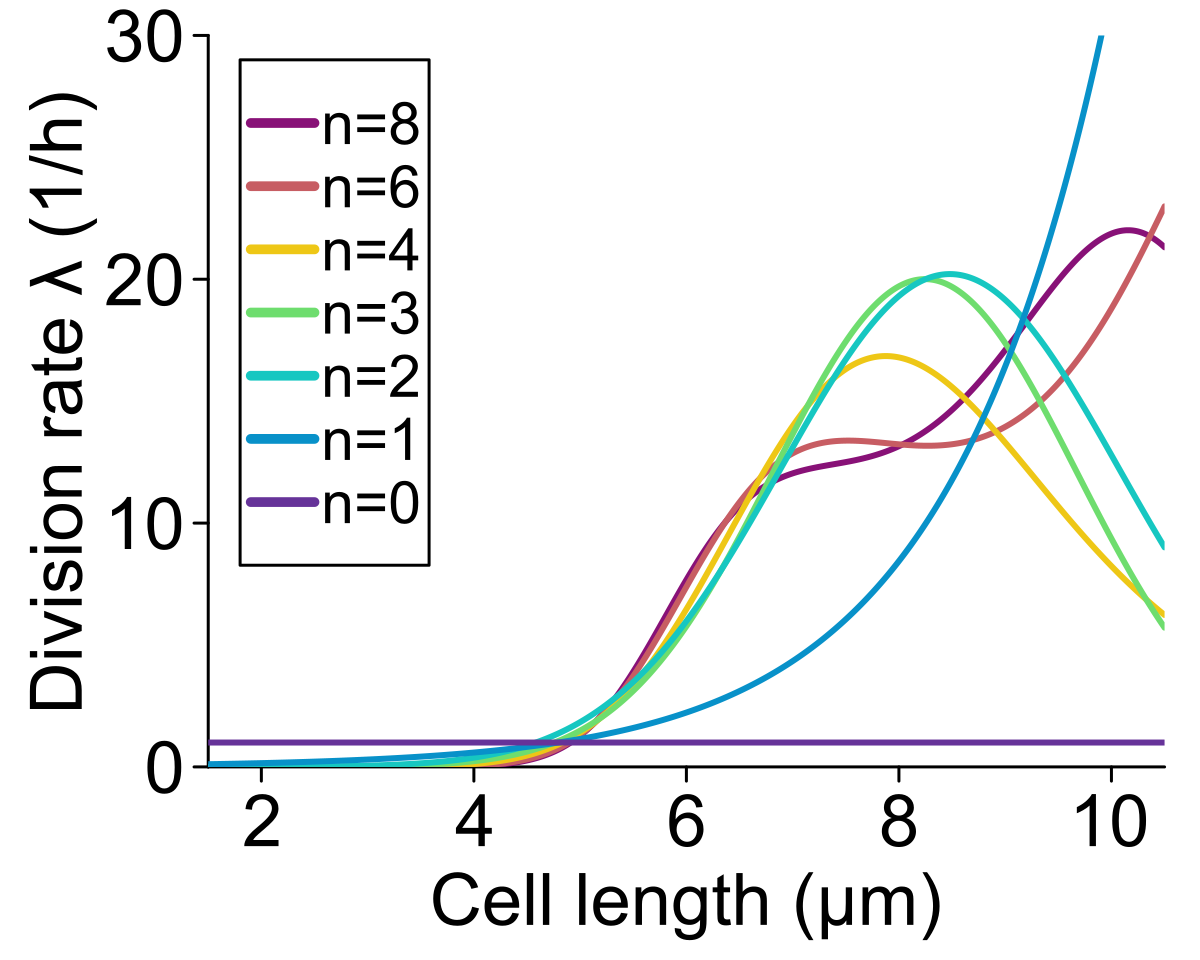

In [78]:
uu = collect(1.5:0.01:10.5);
p2 = plot(;legend=true, ylim=(0,30), ytick=collect(0:10:40), xlim=(1.5, 10.5), xtick=collect(2:2:10), ylabel="Division rate λ (1/h)", xlabel="Cell length (μm)")

history_cl = palette(:twelvebitrainbow, length(history[:coeffs]))
for i in 1:length(history[:coeffs])
    logλ_sparse = rec_ortho_bases(uu, Σ, history[:coeffs][i]);
    plot!(p2, uu, exp.(logλ_sparse), label="n=$(history[:nterms][i])", lc=history_cl[i])
end
p2

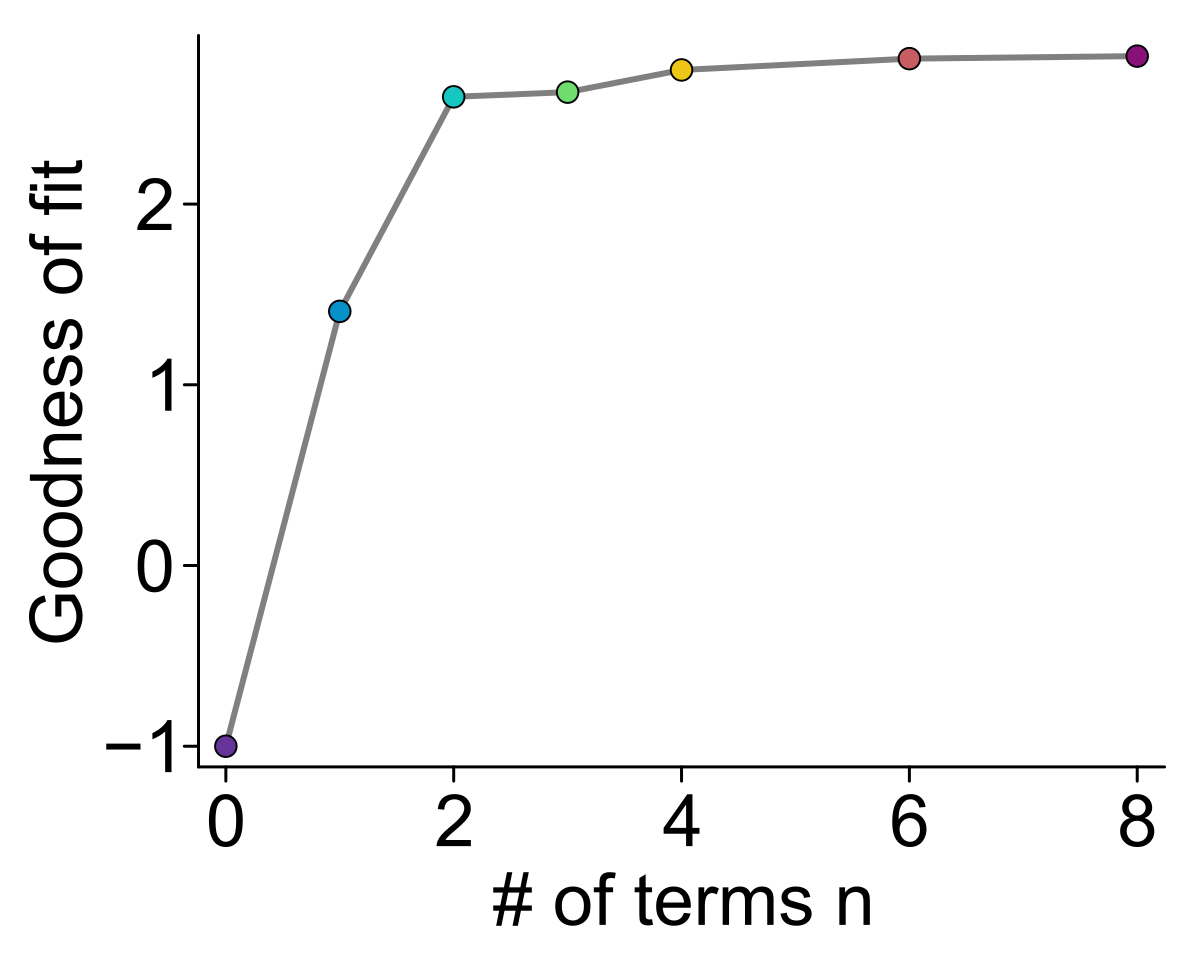

In [77]:
p3 = plot(; ylabel="Goodness of fit", xlabel="# of terms n")
plot!(p3, history[:nterms], -history[:error])
scatter!(p3, history[:nterms], -history[:error]; zcolor=collect(1:length(history[:nterms])), mc=:twelvebitrainbow)